# 03 - Modeling and evaluation
CRISP-DM phases 4-5. Training itself is `python -m src.train` (stratified 5-fold CV on the 80% training split, test split untouched until the end). This notebook reads the saved results and checks them.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
sys.path.insert(0, str(Path.cwd()))
from src.config import load_settings
from src.data.loader import load_sessions, stratified_split
from src.features.engineering import add_engineered_features
from src.utils import metrics as M
S = load_settings()
df = load_sessions(S)

In [2]:
R = json.load(open(S.path('model_dir') / 'metrics.json'))
print('backend:', R['backend']); print('models trained:', R['models_available'])
print('champion:', R['champion'], '| rule:', R['champion_rule']['rule'])
print('best by raw mean PR-AUC would have been:', R['champion_by_max_pr_auc'])

backend: mini_sklearn (NumPy fallback implementing the scikit-learn API subset)
models trained: ['LogisticRegression', 'DecisionTree', 'RandomForest', 'GradientBoosting']
champion: LogisticRegression | rule: simplest model within 1 standard error of the best CV PR-AUC
best by raw mean PR-AUC would have been: RandomForest


**Important honesty notes.** (1) This build environment could not install XGBoost, LightGBM or CatBoost, so only **four** of the six required algorithms were trained here (LogisticRegression, DecisionTree, RandomForest, GradientBoosting). The trainer registers the other three automatically when the packages are installed: run `pip install -r requirements.txt` and `python -m src.train` to get all six. (2) The first run showed LogisticRegression and RandomForest tied to three decimals, so the one-standard-error rule (simplest model within 1 SE of the best) was adopted *after* seeing that; the raw-best alternative is reported above and its test numbers are in the table below.

In [3]:
pd.DataFrame(R['imbalance_benchmark']).drop(columns=['seconds']).round(4)

,model,imbalance,roc_auc,roc_auc_std,pr_auc,pr_auc_std
0,LogisticRegression,none,0.8286,0.0132,0.5237,0.0291
1,LogisticRegression,class_weight,0.8273,0.0137,0.5185,0.0280
2,LogisticRegression,smote,0.8236,0.0138,0.5144,0.0296
3,DecisionTree,none,0.8143,0.0108,0.4815,0.0108
4,DecisionTree,class_weight,0.8048,0.0175,0.4784,0.0128
5,DecisionTree,smote,0.7859,0.0120,0.4289,0.0381
6,RandomForest,none,0.8289,0.0125,0.5315,0.0257
7,RandomForest,class_weight,0.8305,0.0115,0.5272,0.0260
8,RandomForest,smote,0.8279,0.0112,0.5026,0.0301
9,GradientBoosting,none,0.8306,0.0122,0.5182,0.0202


**Takeaway:** the imbalance strategy matters less than expected. `none` / `class_weight` are within noise for every model, and **SMOTE is never better and often worse** (e.g. DecisionTree 0.429 vs 0.482). Plain threshold tuning on un-weighted probabilities is therefore used where it ties, and it keeps probabilities calibrated.

In [4]:
comp = pd.DataFrame(R['comparison']).drop(columns=['params'])
comp['test_pr_auc'] = [R['test_all_models'][m]['pr_auc'] for m in comp.model]
comp['test_roc_auc'] = [R['test_all_models'][m]['roc_auc'] for m in comp.model]
comp.round(4)

,model,imbalance,roc_auc,roc_auc_std,pr_auc,pr_auc_std,brier_oof,seconds,test_pr_auc,test_roc_auc
0,LogisticRegression,none,0.8315,0.0124,0.5313,0.0281,0.0998,0.6359,0.5551,0.8364
1,DecisionTree,none,0.8024,0.0144,0.4887,0.0200,0.1047,1.0696,0.4792,0.7973
2,RandomForest,none,0.8297,0.0117,0.5319,0.0246,0.0994,21.2346,0.5433,0.8319
3,GradientBoosting,class_weight,0.8297,0.0122,0.5214,0.0207,0.1591,32.6839,0.5529,0.8354


**Takeaway:** all non-tree-stump models land within roughly one standard error of each other (CV PR-AUC 0.52-0.53, std 0.02-0.03); the single DecisionTree is clearly worse. GradientBoosting's Brier score (0.159) is much worse than the others (about 0.10) because it was trained with balanced class weights, which distorts its probabilities; do not use its raw probabilities for the value-based threshold.

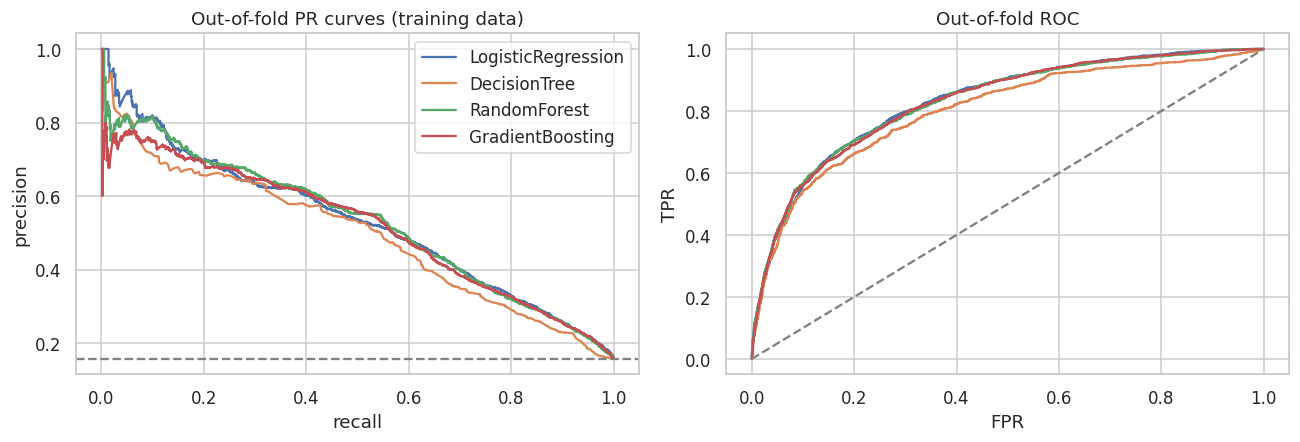

In [5]:
oof = pd.read_csv(S.path('reports_dir') / 'oof_predictions.csv')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for c in [c for c in oof.columns if c.startswith('oof_') and c != 'oof_champion_selected']:
    pr, rc, _ = M.pr_curve(oof.y, oof[c]); ax[0].plot(rc, pr, label=c[4:])
    o = np.argsort(-oof[c].values); ys = oof.y.values[o]; ax[1].plot(np.cumsum(1-ys)/(1-ys).sum(), np.cumsum(ys)/ys.sum(), label=c[4:])
ax[0].axhline(oof.y.mean(), ls='--', c='grey'); ax[0].set(xlabel='recall', ylabel='precision', title='Out-of-fold PR curves (training data)'); ax[0].legend()
ax[1].plot([0,1],[0,1],'--',c='grey'); ax[1].set(xlabel='FPR', ylabel='TPR', title='Out-of-fold ROC'); plt.tight_layout(); plt.show()

## Decision threshold from business value (not 0.5)
Net value of flagging a session = value of a captured purchase x purchases flagged - cost per intervention x sessions flagged. **The value (40) and cost (4) are assumptions in `config/config.yaml`, not measured numbers**; replace them with the retailer's figures. The threshold is chosen on training out-of-fold predictions only.

chosen threshold 0.125 | precision 0.324 recall 0.825 flagged 3846


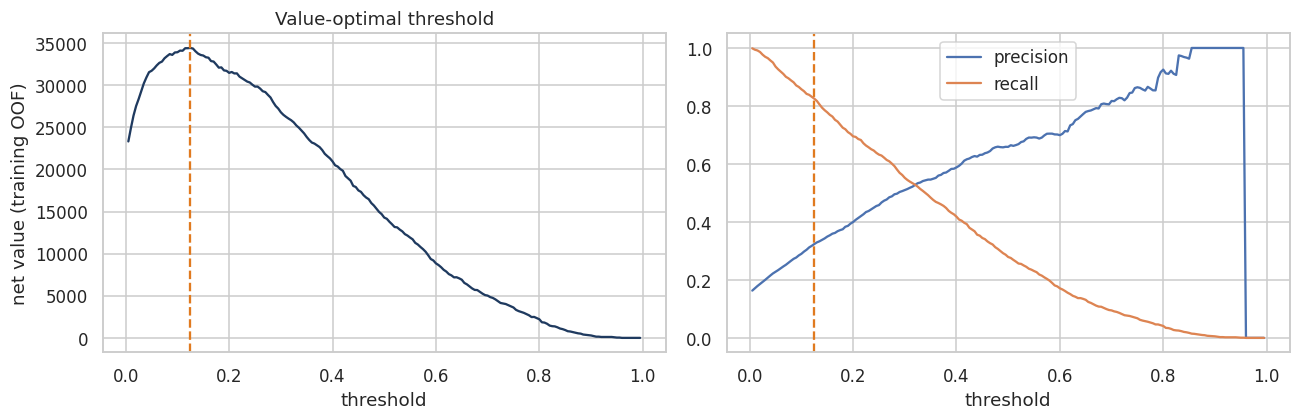

,value_to_cost_ratio,threshold,net_value,precision,recall,flagged
0,2,0.470,4560.0,0.653,0.322,744
1,5,0.255,21704.0,0.467,0.629,2032
2,10,0.125,34416.0,0.324,0.825,3846
3,20,0.045,44430.0,0.222,0.950,6445
4,40,0.020,51519.0,0.186,0.986,8001


In [6]:
vc = pd.read_csv(S.path('reports_dir') / 'value_curve_oof.csv')
t = R['threshold']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(vc.threshold, vc.net_value, c='#1F3A5F'); ax[0].axvline(t['threshold'], c='#E07A1F', ls='--'); ax[0].set(xlabel='threshold', ylabel='net value (training OOF)', title='Value-optimal threshold')
ax[1].plot(vc.threshold, vc.precision, label='precision'); ax[1].plot(vc.threshold, vc.recall, label='recall'); ax[1].axvline(t['threshold'], c='#E07A1F', ls='--'); ax[1].legend(); ax[1].set(xlabel='threshold')
plt.tight_layout(); plt.show()
print('chosen threshold', t['threshold'], '| precision %.3f recall %.3f flagged %d' % (t['precision'], t['recall'], t['flagged']))
pd.DataFrame(R['threshold_sensitivity']).round(3)

**Takeaway:** with value:cost = 10:1 the best threshold is about 0.125 (flag ~40% of sessions, recall 0.82, precision 0.32). The threshold moves from 0.47 to 0.02 as the value:cost ratio goes from 2 to 40 - the model is only half the answer; the business's numbers decide the operating point.

## One evaluation on the untouched test set

In [7]:
T = R['test']
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in T.items() if k not in ('roc_auc_ci95', 'pr_auc_ci95')})
print('ROC-AUC 95% CI', np.round(T['roc_auc_ci95'], 3), '| PR-AUC 95% CI', np.round(T['pr_auc_ci95'], 3))
print('baselines:', json.dumps(R['test_baselines'], indent=1))

{'roc_auc': 0.8365, 'pr_auc': 0.5576, 'brier': 0.0975, 'accuracy': 0.6942, 'precision': 0.3158, 'recall': 0.8117, 'f1': 0.4547, 'flagged_share': 0.4037, 'tn': 1360, 'fp': 663, 'fn': 71, 'tp': 306, 'net_value_test': 8364.0, 'net_value_flag_everyone': 5480.0, 'net_value_flag_nobody': 0.0}
ROC-AUC 95% CI [0.813 0.86 ] | PR-AUC 95% CI [0.505 0.612]
baselines: {
 "majority_class_accuracy": 0.8429166666666666,
 "majority_class_recall": 0.0,
 "random_pr_auc": 0.15708333333333332,
 "single_feature_pr_auc": {
  "ProductRelated": 0.5311109773640874,
  "ExitRates": 0.492706828480099,
  "BounceRates": 0.3667805383597514
 }
}


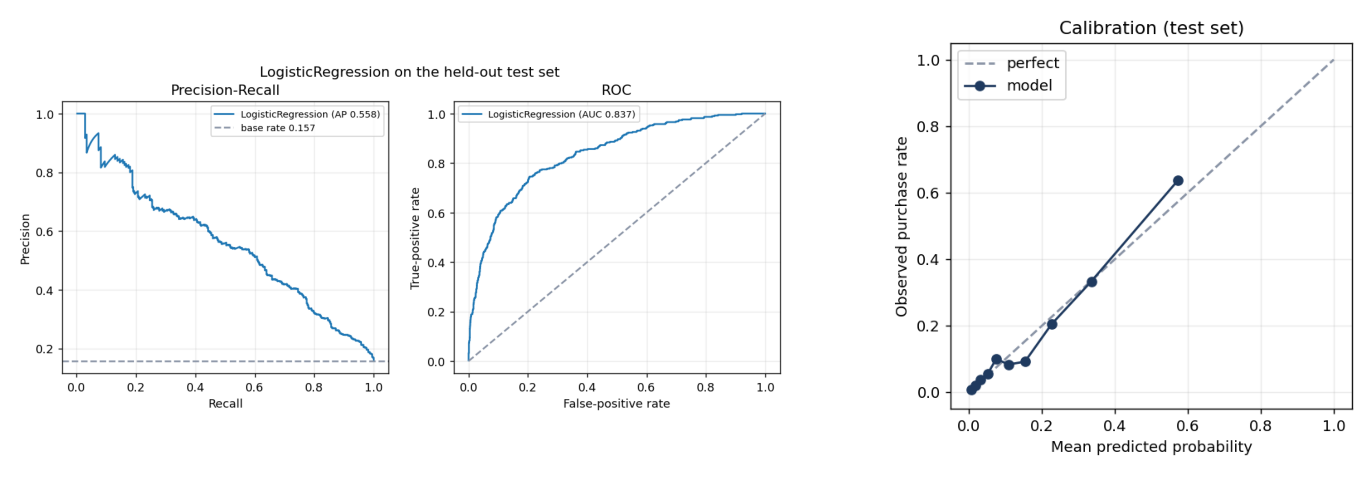

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
import matplotlib.image as mpimg
ax[0].imshow(mpimg.imread(S.path('figures_dir') / 'test_pr_roc.png')); ax[0].axis('off')
ax[1].imshow(mpimg.imread(S.path('figures_dir') / 'test_calibration.png')); ax[1].axis('off')
plt.tight_layout(); plt.show()

**Takeaway (read with the baselines above):** test PR-AUC 0.558 (CI 0.51-0.61) and ROC-AUC 0.837. The model is clearly better than chance (base rate 0.157) and than "always no purchase", but **a single feature, ProductRelated, already gives a test PR-AUC of 0.531**: the full pipeline adds only about 0.03 PR-AUC over a one-line rule. Be careful not to oversell it.

At the chosen threshold the test confusion matrix is TP 306 / FP 663 / FN 71 / TN 1360. Net value on the test set is 8,364 versus 5,480 for flagging everyone and 0 for flagging nobody (under the assumed value and cost); flagging everyone is a strong baseline here because purchases are valuable relative to the intervention cost.

In [9]:
ref = R['test_with_page_values_reference']
print('WITH PageValues (reference only, same recipe):', {k: round(v, 3) for k, v in ref.items() if isinstance(v, float)})
print('WITHOUT PageValues (deployed):                 ROC-AUC %.3f  PR-AUC %.3f' % (T['roc_auc'], T['pr_auc']))

WITH PageValues (reference only, same recipe): {'roc_auc': 0.969, 'pr_auc': 0.853}
WITHOUT PageValues (deployed):                 ROC-AUC 0.837  PR-AUC 0.558


**Takeaway:** adding PageValues lifts test PR-AUC from 0.56 to 0.85 and ROC-AUC from 0.84 to 0.97. That jump is exactly why it must not be used for early-session intervention (see notebook 01); the 0.85 would be a deployment-leakage number. It is shown to quantify the trap, not as a result.

**Limits to keep in mind:** (a) the data holds only whole-session totals, so "score during the session" is not validated here, only "score using final session behaviour"; (b) the value/cost figures are assumed; (c) the data looks synthetic (bounce > exit in 463 rows), so the numbers describe this dataset.